# Notebook 2 — Entrenamiento y comparación de modelos

## Equipo
- Alumno 1 : CHIAPPE, Maximiliano Francisco - C-7542/6
- Alumno 2 : LENARDUZZI, Juan Sebastián - L-3398/7

## Objetivo y protocolo

Comparamos dos modelos que generan **embeddings** de caras:

- **Modelo A:** una CNN propia, entrenada desde cero con nuestro dataset.
- **Modelo B:** ArcFace (`w600k_r50.onnx`, del paquete `buffalo_l` de InsightFace), preentrenado y sin reentrenar.

Usamos el split de la notebook 1 (`splits/splits.csv`):

| Split | Para qué lo usamos |
|---|---|
| `train` (75 personas) | Entrenar la CNN |
| `val` (mismas 75 personas, otras fotos) | Early stopping y curvas de entrenamiento |
| `test` (mismas 75 personas, otras fotos) | Accuracy closed-set del clasificador de la CNN |
| `val_nuevas` (15 personas no vistas) | Calibrar el umbral de similitud |
| `test_nuevas` (otras 15 personas no vistas) | Reportar las métricas finales de verificación, identificación y clustering |

Así, las métricas de los embeddings se miden sobre personas que ningún modelo vio al entrenar, y el umbral se elige con datos distintos de los que usamos para reportar.

## Setup y reproducibilidad

Fijamos las semillas (también la de PyTorch), bajamos la misma versión del dataset, verificamos que el modelo ArcFace sea el mismo archivo y cargamos el split de la notebook 1.

In [22]:
import random
import hashlib
import csv
import numpy as np
import torch
import kagglehub
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True   # reduce las diferencias entre corridas en GPU
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

# Dataset: misma versión que en la notebook 1
path = kagglehub.dataset_download("hereisburak/pins-face-recognition/versions/1")
DATA_DIR = Path(path) / "105_classes_pins_dataset"

# Modelo ArcFace: tiene que ser exactamente el mismo archivo
hash_rec = hashlib.sha256(Path("models/w600k_r50.onnx").read_bytes()).hexdigest()
assert hash_rec == "4c06341c33c2ca1f86781dab0e829f88ad5b64be9fba56e56bc9ebdefc619e43", "w600k_r50.onnx distinto"

# Split generado en la notebook 1
with open("splits/splits.csv", encoding="utf-8") as f:
    filas = list(csv.DictReader(f))

personas = []
split = []
for r in filas:
    personas.append(r["persona"])
    split.append(r["split"])
personas = np.array(personas)
split = np.array(split)

for s in ["train", "val", "test", "val_nuevas", "test_nuevas"]:
    n_imagenes = (split == s).sum()
    n_personas = len(set(personas[split == s]))
    print(f"{s:12} imágenes: {n_imagenes:5}   identidades: {n_personas}")


Dispositivo: cuda
train        imágenes:  9625   identidades: 75
val          imágenes:  1172   identidades: 75
test         imágenes:  1270   identidades: 75
val_nuevas   imágenes:  2418   identidades: 15
test_nuevas  imágenes:  2422   identidades: 15


Corre en GPU y el split es el mismo de la notebook 1: 9625 imágenes para entrenar, 1172 para validar y 1270 de test de las 75 personas conocidas, más 15 personas nuevas para calibrar el umbral (2418 imágenes) y otras 15 para el test final (2422 imágenes).


## Caras alineadas

Los dos modelos tienen que ver exactamente las mismas caras. Tomamos los landmarks que detectamos en la notebook 1 (`data/detecciones.pkl`), alineamos cada cara a 112×112 con `face_pipeline.align` (el mismo código que usa la app) y la pasamos a RGB.

Guardamos el resultado en `data/caras_112.npy` (caché, fuera del repo) para no recalcularlo en cada corrida.

Caras: (16907, 112, 112, 3)


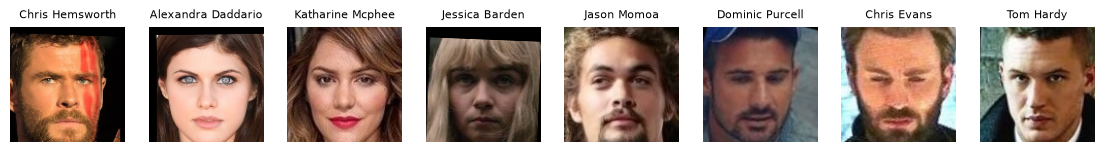

In [23]:
import sys
import pickle
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.append("src")
from lib import face_pipeline

def cara_principal(r):
    # Si hay varias caras, devolvemos la más grande (igual que en la notebook 1)
    areas = []
    for c in r["cajas"]:
        areas.append((c[2] - c[0]) * (c[3] - c[1]))
    i = int(np.argmax(areas))
    return r["cajas"][i], r["puntos"][i]

ARCHIVO_CARAS = Path("data/caras_112.npy")

if ARCHIVO_CARAS.exists():
    caras = np.load(ARCHIVO_CARAS)
else:
    detecciones = pickle.load(open("data/detecciones.pkl", "rb"))

    # Las buscamos por "carpeta/archivo.jpg", igual que en splits.csv
    deteccion = {}
    for r in detecciones:
        clave = Path(r["ruta"]).parent.name + "/" + Path(r["ruta"]).name
        deteccion[clave] = r

    caras = []
    for f in tqdm(filas):
        caja, puntos = cara_principal(deteccion[f["ruta"]])
        img = cv2.imread(str(DATA_DIR / f["ruta"]))
        cara = face_pipeline.align(img, puntos, 112)
        caras.append(cv2.cvtColor(cara, cv2.COLOR_BGR2RGB))
    caras = np.array(caras)
    np.save(ARCHIVO_CARAS, caras)

print("Caras:", caras.shape)

# Algunas caras de train
random.seed(SEED)
ejemplos = random.sample(list(np.where(split == "train")[0]), 8)
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for k, i in enumerate(ejemplos):
    axes[k].imshow(caras[i])
    axes[k].set_title(personas[i], fontsize=8)
    axes[k].axis("off")
plt.show()


Alineamos las 16907 caras en 48 segundos. Todas quedan centradas, con los ojos a la misma altura y del mismo tamaño, que es lo que espera ArcFace. En algunas aparecen esquinas negras (por ejemplo, la 4.ª imagen): al rotar la cara para enderezarla, parte del recuadro queda fuera de la foto original de Pins, que viene recortada muy justa.

Si se alinea de cero (sin el archivo guardado), InsightFace muestra un `FutureWarning` por la versión nueva de scikit-image; no cambia el resultado.


## Modelo A — CNN propia: arquitectura

Usamos el enfoque **clasificación + embedding**: entrenamos la red para clasificar las 75 personas de `train` con cross-entropy y, después, usamos como embedding la capa anterior al clasificador. Es el enfoque más simple para arrancar.

La clase `CustomCNN` está en `src/lib/models/custom_cnn.py`, no en la notebook, para que la app la pueda importar.

Decisiones de diseño:
- **5 bloques conv** (Conv 3×3 → BatchNorm → ReLU → MaxPool): la imagen pasa de 112 a 3 px mientras los canales suben de 32 a 512. Es una red chica a propósito, porque tenemos solo ~9600 imágenes de entrenamiento y una red grande se sobreajustaría.
- **BatchNorm:** estabiliza el entrenamiento y permite usar un learning rate más alto.
- **Global average pooling:** promedia cada canal en un solo número. Así hay muchos menos parámetros que con una capa densa sobre todo el mapa.
- **Dropout (0.3)** antes de la capa de embedding, para reducir el sobreajuste.
- **Embedding de 512:** la misma dimensión que ArcFace y que `EMBEDDING_DIM` de la app.

In [24]:
from lib.models.custom_cnn import CustomCNN

# Las 75 personas de train, cada una con un número de clase
personas_train = sorted(set(personas[split == "train"]))
clase = {}
for i, p in enumerate(personas_train):
    clase[p] = i

modelo_a = CustomCNN(num_classes=len(personas_train)).to(device)
print(modelo_a)

n_total = 0
for p in modelo_a.parameters():
    n_total += p.numel()

n_clasificador = 0
for p in modelo_a.classifier.parameters():
    n_clasificador += p.numel()

print(f"Parámetros: {n_total:,}  (sin el clasificador, que no se exporta: {n_total - n_clasificador:,})")

# Probamos con 2 caras vacías para ver la forma de salida
print("Embedding:", modelo_a(torch.zeros(2, 3, 112, 112, device=device)).shape)


CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, paddin

La red tiene 1.87 millones de parámetros. El clasificador (38 mil) solo sirve para entrenar, así que el modelo que va a la app tiene 1.83 millones, unos 7 MB en float32. Es muy chico: ArcFace (ResNet-50) tiene 43.6 millones, como medimos al final de la notebook. La salida es un embedding de 512 por cara, como esperábamos.


## Modelo A — datos de entrenamiento

Armamos los `DataLoader` de train y val:
- **Augmentation:** el mismo de la notebook 1, aplicado **solo a train** cada vez que el modelo pide una imagen. Val nunca se aumenta.
- **Normalización:** `(x - 127.5) / 127.5` sobre la imagen RGB, igual que `face_pipeline.preprocess` en la app.
- **Batch size 128:** entra cómodo en los 3 GB de la GPU.

In [25]:
import albumentations as A
from torch.utils.data import Dataset, DataLoader

# Mismo augmentation que en la notebook 1
augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=20, val_shift_limit=0, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.15, 0.3), hole_width_range=(0.15, 0.3), p=0.3),
    A.ImageCompression(quality_range=(40, 90), p=0.3),
], seed=SEED)

class CarasDataset(Dataset):
    def __init__(self, indices, aumentar):
        self.indices = indices
        self.aumentar = aumentar

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        i = self.indices[k]
        cara = caras[i]
        if self.aumentar:
            cara = augmentation(image=cara)["image"]
        x = (cara.astype(np.float32) - 127.5) / 127.5   # misma normalización que la app
        return torch.from_numpy(x.transpose(2, 0, 1)), clase[personas[i]]

idx_train = np.where(split == "train")[0]
idx_val = np.where(split == "val")[0]

train_loader = DataLoader(CarasDataset(idx_train, aumentar=True), batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(CarasDataset(idx_val, aumentar=False), batch_size=128)

print("Batches de train:", len(train_loader), " |  Batches de val:", len(val_loader))

Batches de train: 76  |  Batches de val: 10


Con batches de 128 quedan 76 batches de train y 10 de val por época.


## Modelo A — función de entrenamiento

Armamos una función `entrenar` para poder usarla en el entrenamiento principal y después en los experimentos.

Usamos cross-entropy con class weights (las personas con menos fotos pesan más), Adam con `weight_decay=5e-4` como regularización y `ReduceLROnPlateau`, que baja el learning rate a la mitad si la loss de val no mejora en 3 épocas. Si no mejora en 8 épocas cortamos el entrenamiento (early stopping) y nos quedamos con el modelo de la mejor época.

In [26]:
from torch import nn

# Class weights: las personas con menos fotos pesan más en la loss
clases_train = []
for p in personas[idx_train]:
    clases_train.append(clase[p])
conteo = np.bincount(clases_train)

pesos = len(idx_train) / (len(conteo) * conteo)
pesos = torch.tensor(pesos, dtype=torch.float32).to(device)
criterio = nn.CrossEntropyLoss(weight=pesos)

def entrenar(modelo, train_loader, archivo, lr=1e-3, epocas=60, paciencia=8):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.5, patience=3)
    historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor_val_loss = 999
    epocas_sin_mejorar = 0

    for epoca in range(epocas):
        # Entrenamiento
        modelo.train()
        loss_total = 0
        aciertos = 0
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)
            salida = modelo.classifier(modelo(x))
            loss = criterio(salida, y)
            optimizador.zero_grad()
            loss.backward()
            optimizador.step()
            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(1) == y).sum().item()
        historial["train_loss"].append(loss_total / len(idx_train))
        historial["train_acc"].append(aciertos / len(idx_train))

        # Validación
        modelo.eval()
        loss_total = 0
        aciertos = 0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device)
                y = y.to(device)
                salida = modelo.classifier(modelo(x))
                loss = criterio(salida, y)
                loss_total += loss.item() * len(y)
                aciertos += (salida.argmax(1) == y).sum().item()
        historial["val_loss"].append(loss_total / len(idx_val))
        historial["val_acc"].append(aciertos / len(idx_val))

        val_loss = historial["val_loss"][-1]
        scheduler.step(val_loss)
        print("Época", epoca + 1,
              "| train loss", round(historial["train_loss"][-1], 3), "acc", round(historial["train_acc"][-1], 3),
              "| val loss", round(val_loss, 3), "acc", round(historial["val_acc"][-1], 3))

        # Early stopping: guardamos el modelo cada vez que mejora la loss de val
        if val_loss < mejor_val_loss:
            mejor_val_loss = val_loss
            epocas_sin_mejorar = 0
            torch.save(modelo.state_dict(), archivo)
        else:
            epocas_sin_mejorar += 1
            if epocas_sin_mejorar == paciencia:
                print("Early stopping")
                break

    modelo.load_state_dict(torch.load(archivo))   # volvemos a la mejor época
    return historial

print("Pesos de las clases: mín", round(pesos.min().item(), 2), "- máx", round(pesos.max().item(), 2))

Pesos de las clases: mín 0.71 - máx 1.89


Los pesos van de 0.71 (la persona con más fotos) a 1.89 (la que tiene menos). Es la misma diferencia de casi 3 veces que vimos en el EDA de la notebook 1.

## Modelo A — entrenamiento

Entrenamos con learning rate 1e-3 y hasta 60 épocas. Volvemos a crear el modelo con la semilla fija, así el resultado no depende de las celdas anteriores. El mejor checkpoint queda en `models/custom_cnn_mejor.pth` y el historial en `data/historial_a.json` (los dos fuera del repo). Si ya existen, la celda los carga en vez de entrenar de nuevo y muestra el log guardado, época por época.

Hiperparámetros del modelo principal:

| Hiperparámetro | Valor |
|---|---|
| Optimizador | Adam |
| Learning rate inicial | 1e-3 |
| Scheduler | ReduceLROnPlateau (factor 0.5, paciencia 3 épocas) |
| Batch size | 128 |
| Épocas | hasta 60, con early stopping (paciencia 8 épocas) |
| Regularización | weight decay 5e-4, dropout 0.3, augmentation (solo train) |
| Loss | cross-entropy con class weights |
| Entrada | cara alineada 112×112, RGB, normalizada a [-1, 1] |


In [27]:
import time
import json

ARCHIVO_A = Path("models/custom_cnn_mejor.pth")
ARCHIVO_HIST_A = Path("data/historial_a.json")

torch.manual_seed(SEED)
modelo_a = CustomCNN(num_classes=len(personas_train)).to(device)

if ARCHIVO_A.exists() and ARCHIVO_HIST_A.exists():
    # Ya entrenado: cargamos el mejor checkpoint y el historial
    modelo_a.load_state_dict(torch.load(ARCHIVO_A))
    historial_a = json.load(open(ARCHIVO_HIST_A))

    # Mostramos el log del entrenamiento guardado, época por época
    for e in range(len(historial_a["val_loss"])):
        print("Época", e + 1,
              "| train loss", round(historial_a["train_loss"][e], 3), "acc", round(historial_a["train_acc"][e], 3),
              "| val loss", round(historial_a["val_loss"][e], 3), "acc", round(historial_a["val_acc"][e], 3))
else:
    inicio = time.time()
    historial_a = entrenar(modelo_a, train_loader, ARCHIVO_A)
    print("Tiempo de entrenamiento:", round((time.time() - inicio) / 60, 1), "minutos")
    json.dump(historial_a, open(ARCHIVO_HIST_A, "w"))

print("Épocas:", len(historial_a["val_loss"]), "| mejor val loss:", round(min(historial_a["val_loss"]), 3))


Época 1 | train loss 4.305 acc 0.031 | val loss 4.29 acc 0.034
Época 2 | train loss 3.906 acc 0.07 | val loss 4.488 acc 0.067
Época 3 | train loss 3.398 acc 0.142 | val loss 2.947 acc 0.225
Época 4 | train loss 2.878 acc 0.237 | val loss 2.475 acc 0.311
Época 5 | train loss 2.476 acc 0.328 | val loss 2.689 acc 0.295
Época 6 | train loss 2.136 acc 0.406 | val loss 2.207 acc 0.39
Época 7 | train loss 1.833 acc 0.487 | val loss 1.965 acc 0.457
Época 8 | train loss 1.596 acc 0.549 | val loss 1.837 acc 0.48
Época 9 | train loss 1.393 acc 0.607 | val loss 1.622 acc 0.573
Época 10 | train loss 1.241 acc 0.643 | val loss 1.113 acc 0.702
Época 11 | train loss 1.122 acc 0.677 | val loss 1.004 acc 0.708
Época 12 | train loss 1.02 acc 0.708 | val loss 0.864 acc 0.756
Época 13 | train loss 0.935 acc 0.73 | val loss 0.964 acc 0.734
Época 14 | train loss 0.879 acc 0.741 | val loss 0.714 acc 0.805
Época 15 | train loss 0.804 acc 0.761 | val loss 0.737 acc 0.794
Época 16 | train loss 0.778 acc 0.771 | 

Entrenó las 60 épocas en 36 minutos. El early stopping no llegó a cortar: la loss de val siempre volvió a mejorar antes de pasar 8 épocas sin hacerlo. La mejor época fue la 57 (loss de val 0.212, accuracy de val 0.943), y ese es el checkpoint que quedó guardado.

Los saltos de las épocas 34 y 48 coinciden con las veces que el scheduler bajó el learning rate a la mitad. Que la loss de val siguiera bajando casi hasta el final indica que con más épocas todavía podía mejorar un poco.

**Reproducibilidad:** con las mismas semillas, una corrida anterior dio números parecidos pero no idénticos (mejor loss de val 0.205). Algunas operaciones de la GPU suman en un orden que no es fijo, y eso cambia los últimos decimales. Por eso, para la evaluación usamos el checkpoint guardado, que es el mismo del que exportamos `custom_cnn.onnx`.

## Modelo A — curvas de entrenamiento

Graficamos la loss y la accuracy de train y val por época, para ver si hay overfitting (train mejora y val empeora) o underfitting (las dos curvas se estancan en valores malos: loss alta y accuracy baja).

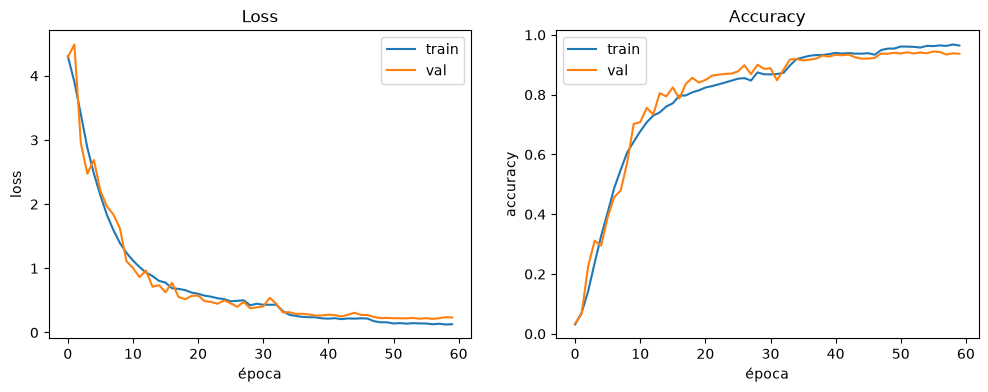

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historial_a["train_loss"], label="train")
axes[0].plot(historial_a["val_loss"], label="val")
axes[0].set_xlabel("época")
axes[0].set_ylabel("loss")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(historial_a["train_acc"], label="train")
axes[1].plot(historial_a["val_acc"], label="val")
axes[1].set_xlabel("época")
axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()

plt.show()


Las curvas de train y val van casi pegadas durante todo el entrenamiento, así que **no hay overfitting fuerte**. Hasta la época 30, val incluso da un poco mejor que train. Esto pasa porque en train las caras llevan augmentation y dropout, y eso las hace más difíciles. Desde la época 48, train queda un poco arriba (96% contra 94%), pero la diferencia es chica. Tampoco hay **underfitting**: train llega a 96% de accuracy.

Desde la época 50, la loss de val se estanca cerca de 0.22, así que más épocas mejorarían muy poco.

Igual, esto mide qué tan bien clasifica a las mismas 75 personas del entrenamiento. Lo que nos importa es si los embeddings separan a personas nuevas, y eso lo medimos en la evaluación.


## Modelo A — experimentos

Probamos variantes del entrenamiento para ver qué aporta cada decisión. Como una corrida de 60 épocas tarda más de media hora, cada experimento entrena 30 épocas, la mitad que el modelo principal. Para que la comparación sea justa, del modelo principal miramos solo sus primeras 30 épocas.

- **Experimento 1, sin augmentation:** para ver cuánto ayuda el augmentation contra el overfitting.
- **Experimento 2, learning rate 3e-3:** para ver si un learning rate más alto aprende más rápido o se vuelve inestable.

Igual que con el modelo principal, el historial se guarda en `data/` y, si ya existe, se carga en vez de entrenar y se muestra el log guardado, época por época.


In [29]:
def mostrar_log(historial):
    for e in range(len(historial["val_loss"])):
        print("Época", e + 1,
              "| train loss", round(historial["train_loss"][e], 3), "acc", round(historial["train_acc"][e], 3),
              "| val loss", round(historial["val_loss"][e], 3), "acc", round(historial["val_acc"][e], 3))

def experimento(nombre, loader, lr):
    archivo = Path(f"data/historial_{nombre}.json")
    if archivo.exists():
        historial = json.load(open(archivo))
        mostrar_log(historial)   # log del entrenamiento guardado
        return historial

    torch.manual_seed(SEED)
    modelo = CustomCNN(num_classes=len(personas_train)).to(device)
    historial = entrenar(modelo, loader, f"models/{nombre}.pth", lr=lr, epocas=30)
    json.dump(historial, open(archivo, "w"))
    return historial

# Experimento 1: mismas imágenes de train, pero sin augmentation
datos_sin_aug = CarasDataset(idx_train, aumentar=False)
train_loader_sin_aug = DataLoader(datos_sin_aug, batch_size=128, shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED))
historial_exp1 = experimento("exp1_sin_aug", train_loader_sin_aug, lr=1e-3)


Época 1 | train loss 3.856 acc 0.089 | val loss 3.323 acc 0.169
Época 2 | train loss 2.758 acc 0.274 | val loss 3.115 acc 0.2
Época 3 | train loss 1.966 acc 0.462 | val loss 2.376 acc 0.38
Época 4 | train loss 1.373 acc 0.62 | val loss 2.431 acc 0.383
Época 5 | train loss 0.963 acc 0.731 | val loss 2.376 acc 0.369
Época 6 | train loss 0.637 acc 0.826 | val loss 1.301 acc 0.637
Época 7 | train loss 0.447 acc 0.879 | val loss 1.283 acc 0.654
Época 8 | train loss 0.271 acc 0.927 | val loss 1.873 acc 0.544
Época 9 | train loss 0.199 acc 0.951 | val loss 0.794 acc 0.783
Época 10 | train loss 0.131 acc 0.97 | val loss 0.993 acc 0.75
Época 11 | train loss 0.109 acc 0.975 | val loss 0.861 acc 0.776
Época 12 | train loss 0.108 acc 0.975 | val loss 0.841 acc 0.776
Época 13 | train loss 0.086 acc 0.982 | val loss 0.805 acc 0.808
Época 14 | train loss 0.037 acc 0.995 | val loss 0.454 acc 0.878
Época 15 | train loss 0.016 acc 0.999 | val loss 0.423 acc 0.892
Época 16 | train loss 0.012 acc 1.0 | va

Sin augmentation hay **overfitting claro**: desde la época 16, train llega al 100% de accuracy con una loss casi en 0, mientras val se queda cerca del 90%. Son 10 puntos de diferencia: el modelo memoriza las fotos de train.

Al principio aprende más rápido (en la época 9 ya tiene 78% en val), pero después se estanca. La mejor loss de val fue 0.382, en la época 26, y no bajó más.

A las 30 épocas los dos modelos terminan parejos en val: 89.8% sin augmentation y 88.7% con augmentation. La diferencia está en lo que queda por aprender. Sin augmentation, train ya está en 100% y no le queda nada, así que más épocas no lo ayudarían. Con augmentation, train y val siguen avanzando juntos, y el modelo principal llegó a 94% y a una loss de 0.212 a las 60 épocas.


**Experimento 2:** el mismo entrenamiento que el modelo principal (con augmentation), pero con learning rate 3e-3 en lugar de 1e-3.


In [30]:
historial_exp2 = experimento("exp2_lr_3e-3", train_loader, lr=3e-3)

Época 1 | train loss 4.519 acc 0.028 | val loss 4.4 acc 0.042
Época 2 | train loss 4.271 acc 0.047 | val loss 4.555 acc 0.039
Época 3 | train loss 3.886 acc 0.078 | val loss 3.553 acc 0.119
Época 4 | train loss 3.463 acc 0.123 | val loss 3.353 acc 0.119
Época 5 | train loss 3.03 acc 0.2 | val loss 3.521 acc 0.16
Época 6 | train loss 2.597 acc 0.296 | val loss 2.403 acc 0.34
Época 7 | train loss 2.335 acc 0.353 | val loss 2.128 acc 0.396
Época 8 | train loss 2.049 acc 0.417 | val loss 2.387 acc 0.348
Época 9 | train loss 1.789 acc 0.495 | val loss 2.396 acc 0.398
Época 10 | train loss 1.637 acc 0.536 | val loss 1.878 acc 0.486
Época 11 | train loss 1.475 acc 0.576 | val loss 1.398 acc 0.6
Época 12 | train loss 1.348 acc 0.615 | val loss 1.144 acc 0.658
Época 13 | train loss 1.28 acc 0.627 | val loss 1.188 acc 0.663
Época 14 | train loss 1.149 acc 0.666 | val loss 1.09 acc 0.685
Época 15 | train loss 1.104 acc 0.678 | val loss 0.938 acc 0.733
Época 16 | train loss 1.035 acc 0.697 | val l

Con learning rate 3e-3 el modelo aprende **más lento y de forma más inestable**. La loss de val salta mucho de una época a otra (por ejemplo, de 0.686 en la época 19 a 1.157 en la 21), porque los pasos del optimizador son demasiado grandes. En sus 30 épocas, la mejor loss de val es 0.598 (época 29), peor que la del modelo principal en esas mismas épocas (0.376).

## Modelo A — comparación de experimentos

Comparamos los tres entrenamientos en sus primeras 30 épocas. De cada uno tomamos la época con mejor loss de val.


Principal (augmentation, lr 1e-3) | mejor época 29 | val loss 0.376 | val acc 0.9 | train acc 0.874
Exp 1: sin augmentation | mejor época 26 | val loss 0.382 | val acc 0.902 | train acc 1.0
Exp 2: lr 3e-3 | mejor época 29 | val loss 0.598 | val acc 0.839 | train acc 0.797


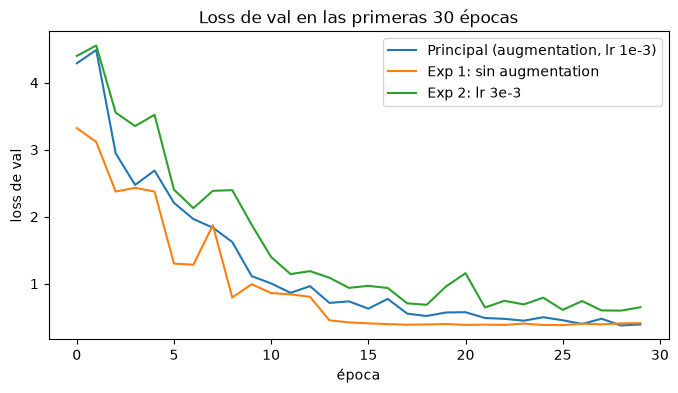

In [31]:
historiales = {
    "Principal (augmentation, lr 1e-3)": historial_a,
    "Exp 1: sin augmentation": historial_exp1,
    "Exp 2: lr 3e-3": historial_exp2,
}

for nombre, h in historiales.items():
    i = np.argmin(h["val_loss"][:30])   # mejor época dentro de las primeras 30
    print(nombre, "| mejor época", i + 1,
          "| val loss", round(h["val_loss"][i], 3),
          "| val acc", round(h["val_acc"][i], 3),
          "| train acc", round(h["train_acc"][i], 3))

plt.figure(figsize=(8, 4))
for nombre, h in historiales.items():
    plt.plot(h["val_loss"][:30], label=nombre)
plt.xlabel("época")
plt.ylabel("loss de val")
plt.title("Loss de val en las primeras 30 épocas")
plt.legend()
plt.show()

Tabla de experimentos, con una fila por entrenamiento. Los experimentos duran 30 épocas y el principal 60, así que comparamos a todos en sus primeras 30 épocas y además mostramos el mejor resultado de cada uno.

| Entrenamiento | Épocas | Primeras 30 épocas: loss val / acc val / acc train | Mejor resultado: época, loss val / acc val | Conclusión |
|---|---|---|---|---|
| Principal: augmentation, lr 1e-3 | 60 | 0.376 / 0.900 / 0.874 | época 57: 0.212 / 0.943 | Train y val van juntos y sigue mejorando. **Elegido** |
| Exp 1: sin augmentation | 30 | 0.382 / 0.902 / 1.000 | época 26: 0.382 / 0.902 | Overfitting: memoriza train y se estanca |
| Exp 2: lr 3e-3 | 30 | 0.598 / 0.839 / 0.797 | época 29: 0.598 / 0.839 | Inestable y más lento: no funcionó |

A las 30 épocas, el modelo sin augmentation llega a la misma accuracy de val que el principal, pero ya tiene 100% en train: no le queda nada por aprender y no mejora más. El principal, en cambio, sigue mejorando y llega a 94% a las 60 épocas. Con learning rate 3e-3 la loss de val oscila mucho y el resultado queda bastante peor. Nos quedamos con el modelo principal.

## Modelo B — ArcFace preentrenado

Usamos los modelos del paquete **`buffalo_l` de InsightFace**, sin reentrenar:

- **Detector:** `det_10g.onnx`, un SCRFD entrenado con WIDER FACE. Devuelve la caja y 5 landmarks por cara. Es el mismo que usamos en la notebook 1 para detectar y alinear, así que los dos modelos reciben exactamente las mismas caras.
- **Reconocedor:** `w600k_r50.onnx`, una ResNet-50 entrenada con la loss ArcFace (margen angular) sobre WebFace600K, un dataset de unas 600 mil personas. Recibe la cara alineada de 112×112 y devuelve un embedding de dimensión **512**. Es el modelo que usa la app.
- **Licencia:** según el README de InsightFace, el código es MIT pero **los modelos preentrenados son solo para investigación no comercial**. Para un TP está bien; para usarlo en un producto habría que licenciarlo o entrenar uno propio.

## Embeddings de los dos modelos

Calculamos los embeddings de los dos modelos para las 30 personas nuevas (`val_nuevas` y `test_nuevas`), que son las que usamos en toda la evaluación. Los dos modelos usan `face_pipeline.preprocess` y `l2_normalize`, igual que la app. Antes de procesar, pasamos la cara a BGR, porque `preprocess` espera la imagen tal como la lee OpenCV.

Los embeddings de ArcFace tardan unos minutos en CPU, así que los guardamos en `data/`. Los de la CNN se calculan en la GPU en segundos y no hace falta guardarlos.

In [32]:
import onnxruntime

idx_eval = np.where((split == "val_nuevas") | (split == "test_nuevas"))[0]

# Modelo B: ArcFace
arcface = onnxruntime.InferenceSession("models/w600k_r50.onnx")
entrada = arcface.get_inputs()[0].name

ARCHIVO_EMB_B = Path("data/embeddings_arcface_eval.npy")
if ARCHIVO_EMB_B.exists():
    emb_b = np.load(ARCHIVO_EMB_B)
else:
    emb_b = []
    for i in tqdm(idx_eval):
        cara_bgr = cv2.cvtColor(caras[i], cv2.COLOR_RGB2BGR)
        x = face_pipeline.preprocess(cara_bgr)
        emb = arcface.run(None, {entrada: x})[0]
        emb_b.append(face_pipeline.l2_normalize(emb))
    emb_b = np.array(emb_b)
    np.save(ARCHIVO_EMB_B, emb_b)

# Modelo A: nuestra CNN
modelo_a.eval()
emb_a = []
with torch.no_grad():
    for i in tqdm(idx_eval):
        cara_bgr = cv2.cvtColor(caras[i], cv2.COLOR_RGB2BGR)
        x = torch.from_numpy(face_pipeline.preprocess(cara_bgr)).to(device)
        emb = modelo_a(x).cpu().numpy()
        emb_a.append(face_pipeline.l2_normalize(emb))
emb_a = np.array(emb_a)

print("Embeddings A:", emb_a.shape, "| Embeddings B:", emb_b.shape)


100%|██████████| 4840/4840 [00:08<00:00, 544.38it/s]

Embeddings A: (4840, 512) | Embeddings B: (4840, 512)


Tenemos 4840 embeddings de dimensión 512 por modelo, uno por cada imagen de `val_nuevas` y `test_nuevas`. La primera vez, ArcFace tardó unos 6.5 minutos en CPU (unas 12 caras por segundo); ahora se cargan desde `data/`. Nuestra CNN, en GPU, tarda menos de un minuto. El costo de los dos modelos lo comparamos de forma justa, ambos en CPU, en la sección de costo computacional.


## Verificación — pares de caras

Para verificación ("¿son la misma persona?") armamos pares de imágenes: **positivos** (misma persona) y **negativos** (personas distintas). Elegimos 20000 de cada tipo al azar, con semilla fija.

Armamos pares por separado para `val_nuevas`, que usamos para calibrar el umbral, y para `test_nuevas`, que usamos para reportar. Los dos modelos se evalúan con **los mismos pares**. La similitud de un par es el coseno entre sus embeddings. Como los embeddings están normalizados, ese coseno es igual al producto punto.

In [33]:
pers_eval = personas[idx_eval]
split_eval = split[idx_eval]

def armar_pares(nombre_split, n=20000):
    rng = np.random.default_rng(SEED)
    idx = np.where(split_eval == nombre_split)[0]
    positivos = []
    negativos = []
    while len(positivos) < n or len(negativos) < n:
        i, j = rng.choice(idx, 2, replace=False)
        if pers_eval[i] == pers_eval[j] and len(positivos) < n:
            positivos.append((i, j))
        if pers_eval[i] != pers_eval[j] and len(negativos) < n:
            negativos.append((i, j))
    pares = np.array(positivos + negativos)
    y = np.array([1] * n + [0] * n)   # 1 = misma persona
    return pares, y

def similitudes(emb, pares):
    return np.sum(emb[pares[:, 0]] * emb[pares[:, 1]], axis=1)

pares_val, y_val = armar_pares("val_nuevas")
pares_test, y_test = armar_pares("test_nuevas")

sim_val_a = similitudes(emb_a, pares_val)
sim_val_b = similitudes(emb_b, pares_val)
sim_test_a = similitudes(emb_a, pares_test)
sim_test_b = similitudes(emb_b, pares_test)

print("Pares de val:", len(pares_val), "| Pares de test:", len(pares_test))
print("Similitud media en test (positivos / negativos):")
print("  CNN:    ", round(sim_test_a[y_test == 1].mean(), 3), "/", round(sim_test_a[y_test == 0].mean(), 3))
print("  ArcFace:", round(sim_test_b[y_test == 1].mean(), 3), "/", round(sim_test_b[y_test == 0].mean(), 3))


Pares de val: 40000 | Pares de test: 40000
Similitud media en test (positivos / negativos):
  CNN:     0.395 / 0.03
  ArcFace: 0.562 / 0.017


Los dos modelos dan, en promedio, más similitud a los pares de la misma persona que a los de personas distintas. En los negativos, los dos quedan cerca de 0 (0.03 y 0.017). En los positivos, ArcFace da bastante más alto: 0.562 contra 0.395. Eso indica que ArcFace separa mejor. Igual, el promedio no alcanza para comparar, así que lo medimos bien con la curva ROC.

## Verificación — ROC, AUC, EER y TAR@FAR (test)

Con las similitudes de los pares de `test_nuevas` calculamos:
- **Curva ROC:** para cada umbral posible, la **TAR** (pares de la misma persona aceptados) contra la **FAR** (pares de personas distintas aceptados por error).
- **AUC:** el área bajo la curva ROC. 1 es perfecto y 0.5 es azar.
- **EER:** el error en el punto donde la FAR es igual a la FRR (pares de la misma persona rechazados). Cuanto más bajo, mejor.
- **TAR@FAR:** cuántos pares de la misma persona se aceptan cuando solo se permite aceptar por error 1 de cada 100 (1e-2) o 1 de cada 1000 (1e-3) pares de personas distintas. Es la métrica que importa en un sistema real, donde aceptar a otra persona es el error grave.

El eje de la FAR va en escala logarítmica para que se vea bien la zona de FAR baja.

AUC | CNN: 0.9008 | ArcFace: 1.0
EER | CNN: 0.1847 | ArcFace: 0.0017
TAR@FAR=1e-2 | CNN: 0.3104 | ArcFace: 0.9993
TAR@FAR=1e-3 | CNN: 0.134 | ArcFace: 0.998


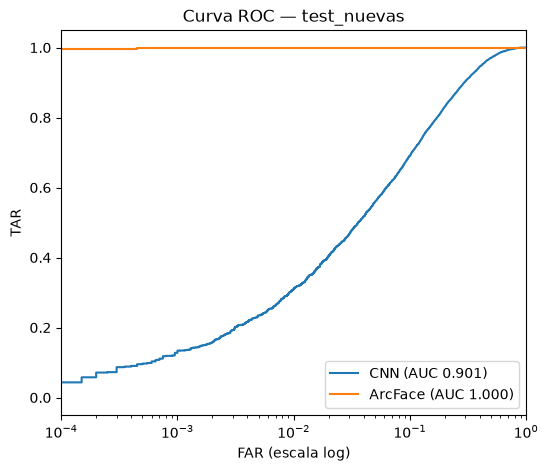

In [34]:
from sklearn.metrics import roc_curve, roc_auc_score

def metricas_verificacion(sim, y):
    far, tar, umbrales = roc_curve(y, sim)
    frr = 1 - tar
    k = np.argmin(np.abs(far - frr))   # punto donde FAR = FRR
    resultados = {
        "AUC": roc_auc_score(y, sim),
        "EER": (far[k] + frr[k]) / 2,
        "TAR@FAR=1e-2": tar[far <= 1e-2].max(),
        "TAR@FAR=1e-3": tar[far <= 1e-3].max(),
    }
    return resultados, far, tar

ver_a, far_a, tar_a = metricas_verificacion(sim_test_a, y_test)
ver_b, far_b, tar_b = metricas_verificacion(sim_test_b, y_test)

for m in ver_a:
    print(m, "| CNN:", round(ver_a[m], 4), "| ArcFace:", round(ver_b[m], 4))

plt.figure(figsize=(6, 5))
plt.plot(far_a, tar_a, label=f"CNN (AUC {ver_a['AUC']:.3f})")
plt.plot(far_b, tar_b, label=f"ArcFace (AUC {ver_b['AUC']:.3f})")
plt.xscale("log")
plt.xlim(1e-4, 1)
plt.xlabel("FAR (escala log)")
plt.ylabel("TAR")
plt.title("Curva ROC — test_nuevas")
plt.legend()
plt.show()

| Métrica (test_nuevas) | CNN | ArcFace |
|---|---|---|
| AUC | 0.901 | 1.000 |
| EER | 18.5% | 0.17% |
| TAR@FAR=1e-2 | 31.0% | 99.9% |
| TAR@FAR=1e-3 | 13.4% | 99.8% |

ArcFace es casi perfecto: su AUC da 1.000 redondeado, pero no es exactamente 1, porque tiene un EER de 0.17%. Aun aceptando por error a otra persona solo 1 de cada 1000 veces, reconoce el 99.8% de los pares de la misma persona.

Nuestra CNN tiene un AUC de 0.90, así que aprendió algo útil para personas que nunca vio, pero queda muy lejos de ArcFace. Para aceptar a otra persona solo 1 de cada 1000 veces, tiene que rechazar el 87% de los pares de la misma persona. En la app, eso significaría no reconocer a casi nadie.

**A tener en cuenta sobre ArcFace:** WebFace, el dataset con el que se entrenó, está armado con fotos de famosos sacadas de internet, igual que Pins. Es probable que ArcFace haya visto a varias de nuestras "personas nuevas" durante su entrenamiento, y entonces su resultado puede ser optimista. No lo podemos verificar porque no tenemos la lista de identidades de WebFace. Para nuestra CNN, en cambio, sí sabemos que estas 15 personas son nuevas.


## Verificación — histograma de similitudes (test)

Graficamos cómo se reparten las similitudes de los pares de la misma persona y de los pares de personas distintas. Si un modelo separa bien, los dos histogramas casi no se superponen y en el medio queda un rango de umbrales que los divide.

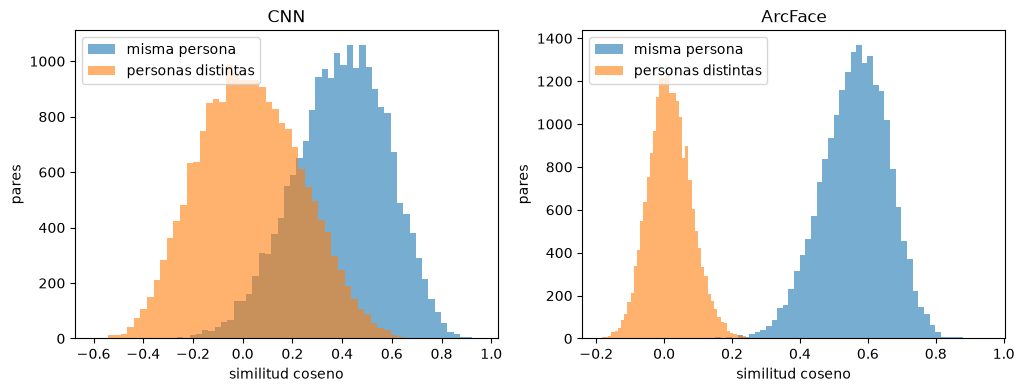

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

modelos = [("CNN", sim_test_a), ("ArcFace", sim_test_b)]
for k in range(2):
    nombre, sim = modelos[k]
    axes[k].hist(sim[y_test == 1], bins=50, alpha=0.6, label="misma persona")
    axes[k].hist(sim[y_test == 0], bins=50, alpha=0.6, label="personas distintas")
    axes[k].set_xlabel("similitud coseno")
    axes[k].set_ylabel("pares")
    axes[k].set_title(nombre)
    axes[k].legend()

plt.show()


En ArcFace los dos histogramas están **separados**. Los pares de personas distintas quedan entre -0.2 y 0.25, y los de la misma persona entre 0.25 y 0.9. Se tocan apenas alrededor de 0.25.

En la CNN, en cambio, **se superponen mucho**, sobre todo entre 0 y 0.6, y ningún umbral los separa bien. Si lo subimos, rechazamos a muchos pares de la misma persona. Si lo bajamos, aceptamos a muchos pares de personas distintas. Es lo mismo que mostraba la curva ROC.


## Elección del umbral (val_nuevas)

La app usa `SIMILARITY_THRESHOLD`: si la similitud con la persona más parecida de la galería queda por debajo del umbral, responde `unknown`. Lo calibramos con los pares de **`val_nuevas`** y no con los de test, para no elegirlo con los mismos datos sobre los que reportamos.

Graficamos la FAR y la FRR en función del umbral y miramos dos criterios:
- **Umbral EER:** donde FAR = FRR, es decir, donde los dos errores pesan lo mismo.
- **Umbral para FAR = 1e-3:** el umbral más bajo que acepta por error a otra persona como máximo 1 de cada 1000 veces.

Para la app preferimos el segundo. Confundir a alguien con otra persona registrada es el error grave. En cambio, si el sistema no reconoce a alguien, esa persona puede volver a intentar con otra foto.

Después controlamos en test qué FAR y FRR da el umbral elegido.


CNN | umbral EER: 0.218 | umbral FAR=1e-3: 0.618
   en test con el umbral FAR=1e-3 -> FAR: 0.0008 | FRR: 0.8886
ArcFace | umbral EER: 0.224 | umbral FAR=1e-3: 0.268
   en test con el umbral FAR=1e-3 -> FAR: 0.0002 | FRR: 0.0034


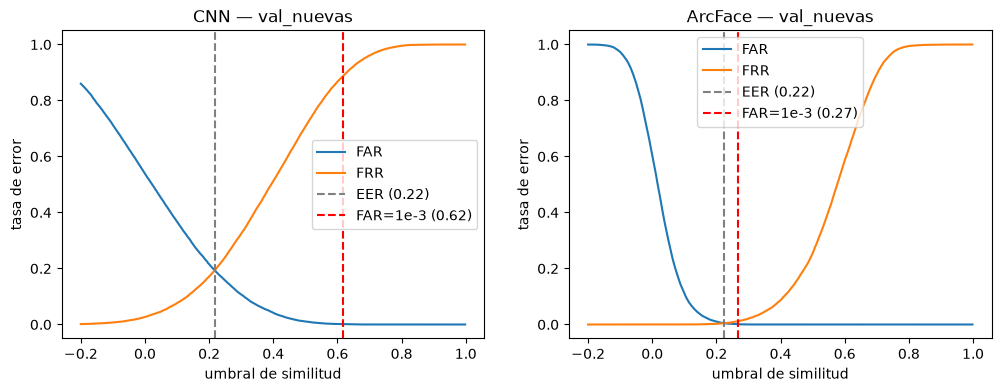

In [36]:
umbrales = np.arange(-0.2, 1.0, 0.002)

def curvas_far_frr(sim, y):
    far = []
    frr = []
    for u in umbrales:
        far.append((sim[y == 0] >= u).mean())   # distintos aceptados
        frr.append((sim[y == 1] < u).mean())    # misma persona rechazada
    return np.array(far), np.array(frr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
modelos = [("CNN", sim_val_a, sim_test_a), ("ArcFace", sim_val_b, sim_test_b)]
umbral_elegido = {}

for k in range(2):
    nombre, sim_val, sim_test = modelos[k]
    far, frr = curvas_far_frr(sim_val, y_val)
    u_eer = umbrales[np.argmin(np.abs(far - frr))]
    u_far = umbrales[np.where(far <= 1e-3)[0][0]]   # primer umbral con FAR <= 1e-3
    umbral_elegido[nombre] = u_far

    far_test = (sim_test[y_test == 0] >= u_far).mean()
    frr_test = (sim_test[y_test == 1] < u_far).mean()
    print(nombre, "| umbral EER:", round(u_eer, 3), "| umbral FAR=1e-3:", round(u_far, 3))
    print("   en test con el umbral FAR=1e-3 -> FAR:", round(far_test, 4), "| FRR:", round(frr_test, 4))

    axes[k].plot(umbrales, far, label="FAR")
    axes[k].plot(umbrales, frr, label="FRR")
    axes[k].axvline(u_eer, color="gray", linestyle="--", label=f"EER ({u_eer:.2f})")
    axes[k].axvline(u_far, color="red", linestyle="--", label=f"FAR=1e-3 ({u_far:.2f})")
    axes[k].set_xlabel("umbral de similitud")
    axes[k].set_ylabel("tasa de error")
    axes[k].set_title(nombre + " — val_nuevas")
    axes[k].legend()

plt.show()


| | CNN | ArcFace |
|---|---|---|
| Umbral EER (val) | 0.218 | 0.224 |
| Umbral FAR=1e-3 (val) | 0.618 | 0.268 |
| FAR en test con ese umbral | 0.08% | 0.02% |
| FRR en test con ese umbral | 88.9% | 0.34% |

El umbral calibrado en val **funciona igual en test**: la FAR queda por debajo de 1e-3 en los dos modelos. O sea, el umbral generaliza a personas que no se usaron para elegirlo.

Con ArcFace, un umbral de **0.27** casi no comete errores: acepta por error a otra persona 2 de cada 10000 veces y rechaza solo el 0.34% de los pares de la misma persona. Con la CNN, para tener esa misma seguridad hay que subir el umbral a 0.62, y ahí rechaza el 89% de los pares de la misma persona. Con un umbral seguro, la CNN no sirve.

La app traía por defecto `SIMILARITY_THRESHOLD=0.55`. Con ArcFace ese valor es demasiado exigente: según el gráfico, rechazaría a más de un tercio de las personas registradas. Por eso, en `.env.docker.example` y `.env.local.example` lo cambiamos a **0.27**.


## Identificación — galería y consultas (test)

Para identificación ("¿quién es?") imitamos el uso de la app con las 15 personas de `test_nuevas`:
- **Galería:** elegimos al azar 10 personas y "registramos" 5 fotos de cada una, como si se cargaran con `/insert`.
- **Consultas:** el resto de las fotos de esas 10 personas, más todas las fotos de las otras 5 personas. Esas 5 **no están registradas**, así que deberían salir como `unknown`.

Para cada consulta hacemos lo mismo que `FaceService.identify` en la app: buscamos la foto de la galería con mayor similitud y, si esa similitud queda por debajo del umbral, la respuesta es `unknown`.

In [37]:
random.seed(SEED)
personas_test = sorted(set(pers_eval[split_eval == "test_nuevas"]))
registradas = sorted(random.sample(personas_test, 10))

galeria = []
consultas = []
for p in personas_test:
    idx = list(np.where((split_eval == "test_nuevas") & (pers_eval == p))[0])
    random.shuffle(idx)
    if p in registradas:
        galeria += idx[:5]     # 5 fotos registradas
        consultas += idx[5:]   # el resto se usa para consultar
    else:
        consultas += idx       # no registrada: todas sus fotos son consultas
galeria = np.array(galeria)
consultas = np.array(consultas)

# Respuesta correcta de cada consulta: la persona si está registrada, si no "unknown"
verdad = []
for p in pers_eval[consultas]:
    if p in registradas:
        verdad.append(p)
    else:
        verdad.append("unknown")
verdad = np.array(verdad)

print("Galería:", len(galeria), "fotos de", len(registradas), "personas")
print("Consultas:", len(consultas),
      "| de personas registradas:", (verdad != "unknown").sum(),
      "| de personas no registradas:", (verdad == "unknown").sum())

Galería: 50 fotos de 10 personas
Consultas: 2372 | de personas registradas: 1481 | de personas no registradas: 891


La galería tiene 50 fotos (5 por persona registrada) y hay 2372 consultas: 1481 de personas registradas y 891 de personas que no están en la galería.

## Identificación — métricas (test)

Para cada modelo usamos su umbral calibrado en val (el de FAR = 1e-3) y calculamos:
- **Top-1 y Top-5:** solo con las consultas de personas registradas y sin umbral. Ordenamos las 10 personas de la galería según la foto más parecida de cada una, y miramos si la persona correcta sale primera (Top-1) o entre las 5 primeras (Top-5).
- **Precision, recall y F1 (macro):** con el umbral, sobre 11 clases: las 10 personas más `unknown`. Macro quiere decir que se calcula por clase y después se promedia, así cada persona pesa lo mismo.
- **Desconocidos rechazados:** qué porcentaje de las consultas de personas no registradas salió como `unknown`.
- **Registrados reconocidos:** qué porcentaje de las consultas de personas registradas salió con el nombre correcto.

In [38]:
from sklearn.metrics import precision_recall_fscore_support

def identificar(emb, umbral):
    sims = emb[consultas] @ emb[galeria].T   # similitud de cada consulta con cada foto de la galería
    prediccion = pers_eval[galeria][sims.argmax(axis=1)]
    prediccion = np.where(sims.max(axis=1) >= umbral, prediccion, "unknown")
    return prediccion, sims

def top_k(sims, k):
    # Similitud con cada persona registrada = la de su foto más parecida
    por_persona = []
    for p in registradas:
        por_persona.append(sims[:, pers_eval[galeria] == p].max(axis=1))
    por_persona = np.stack(por_persona, axis=1)

    mejores = np.argsort(-por_persona, axis=1)[:, :k]
    aciertos = []
    for i in np.where(verdad != "unknown")[0]:
        aciertos.append(registradas.index(verdad[i]) in mejores[i])
    return np.mean(aciertos)

conocidas = verdad != "unknown"
predicciones = {}
for nombre, emb in [("CNN", emb_a), ("ArcFace", emb_b)]:
    pred, sims = identificar(emb, umbral_elegido[nombre])
    predicciones[nombre] = pred
    precision, recall, f1, _ = precision_recall_fscore_support(verdad, pred, average="macro", zero_division=0)

    print(nombre, "| umbral", round(umbral_elegido[nombre], 3))
    print("  Top-1:", round(top_k(sims, 1), 3), "| Top-5:", round(top_k(sims, 5), 3))
    print("  Precision:", round(precision, 3), "| Recall:", round(recall, 3), "| F1:", round(f1, 3))
    print("  Desconocidos rechazados:", round((pred[~conocidas] == "unknown").mean(), 3))
    print("  Registrados reconocidos:", round((pred[conocidas] == verdad[conocidas]).mean(), 3))


CNN | umbral 0.618
  Top-1: 0.772 | Top-5: 0.986
  Precision: 0.843 | Recall: 0.423 | F1: 0.486
  Desconocidos rechazados: 0.954
  Registrados reconocidos: 0.374
ArcFace | umbral 0.268
  Top-1: 1.0 | Top-5: 1.0
  Precision: 1.0 | Recall: 1.0 | F1: 1.0
  Desconocidos rechazados: 1.0
  Registrados reconocidos: 1.0


| Métrica (test) | CNN | ArcFace |
|---|---|---|
| Top-1 | 77.2% | 100% |
| Top-5 | 98.6% | 100% |
| Precision macro | 0.843 | 1.000 |
| Recall macro | 0.423 | 1.000 |
| F1 macro | 0.486 | 1.000 |
| Desconocidos rechazados | 95.4% | 100% |
| Registrados reconocidos | 37.4% | 100% |

ArcFace acierta las 2372 consultas: siempre pone primera a la persona correcta y rechaza a todos los desconocidos.

La CNN muestra algo interesante: **sin umbral ordena bastante bien**. En el 77% de los casos la persona correcta sale primera entre 10, y casi siempre está entre las 5 primeras. El problema es el umbral. Para no aceptar desconocidos (rechaza el 95%) necesita 0.62, y con ese valor también rechaza a la mayoría de los registrados: reconoce solo al 37%. Por eso la precision es alta (cuando dice un nombre, casi siempre acierta) y el recall es bajo (casi siempre dice `unknown`).


## Identificación — matriz de confusión (test)

Mostramos la matriz de confusión de cada modelo con las 10 personas registradas más `unknown`. Las filas son la respuesta correcta y las columnas, lo que predijo el modelo. Lo ideal es que todo quede en la diagonal. También contamos cuántas consultas salieron mal en total.

CNN | consultas mal identificadas: 968 de 2372
ArcFace | consultas mal identificadas: 0 de 2372


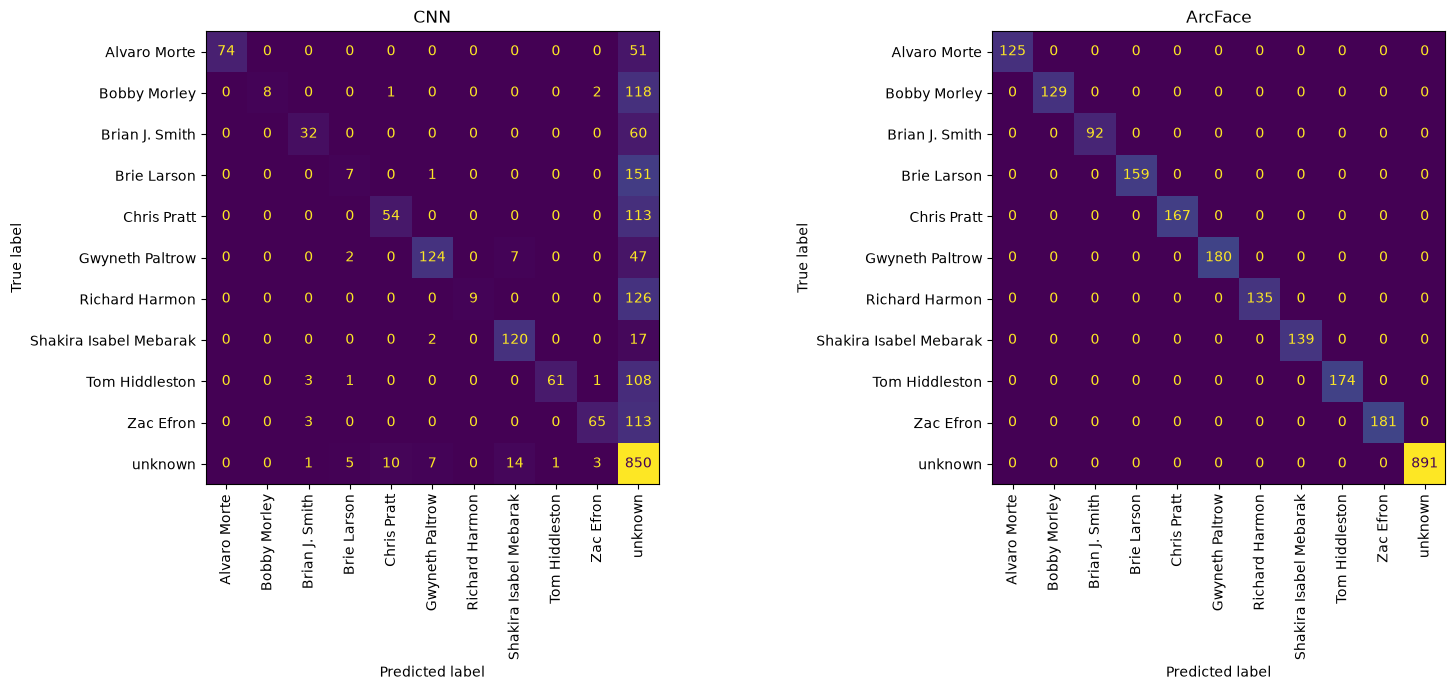

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

etiquetas_cm = registradas + ["unknown"]
nombres = ["CNN", "ArcFace"]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for k in range(2):
    nombre = nombres[k]
    cm = confusion_matrix(verdad, predicciones[nombre], labels=etiquetas_cm)
    ConfusionMatrixDisplay(cm, display_labels=etiquetas_cm).plot(ax=axes[k], colorbar=False, xticks_rotation=90)
    axes[k].set_title(nombre)

    errores = (predicciones[nombre] != verdad).sum()
    print(nombre, "| consultas mal identificadas:", errores, "de", len(verdad))

plt.tight_layout()
plt.show()


ArcFace no se equivocó en ninguna de las 2372 consultas: toda la matriz está en la diagonal.

La CNN se equivocó en 968. Casi todos sus errores (904) son **personas registradas que salieron como `unknown`**, en la última columna. Es el efecto del umbral alto que ya vimos. Entre personas registradas casi no se confunde: son solo 23 casos, y el más repetido es Gwyneth Paltrow tomada como Shakira Isabel Mebarak (7 veces). Además, aceptó a 41 desconocidos como alguien de la galería, sobre todo como Shakira Isabel Mebarak (14) y Chris Pratt (10).

El resultado cambia mucho según la persona. A Shakira Isabel Mebarak la reconoce en el 86% de sus consultas y a Gwyneth Paltrow en el 69%, mientras que a Brie Larson, Bobby Morley y Richard Harmon los reconoce en menos del 7% de sus consultas. Las causas posibles las vemos en el análisis de errores.

## Pipeline completo — de la foto a la respuesta

Hasta acá trabajamos con caras ya detectadas y alineadas. Ahora seguimos el recorrido completo que hace la app con **una foto original del dataset**, desde el archivo hasta la respuesta final:

| Paso | Qué hace | Herramienta |
|---|---|---|
| 1 | Cargar la foto original | `cv2.imread` |
| 2 | Detectar la cara | SCRFD (`det_10g.onnx`) → caja + 5 landmarks |
| 3 | Alinear la cara | `face_pipeline.align` → cara de 112×112 |
| 4 | Generar el embedding | ArcFace (`w600k_r50.onnx`) → vector de 512 |
| 5 | Comparar con la galería y aplicar el umbral | similitud coseno + umbral 0.27 → nombre o `unknown` |

Usamos las mismas funciones de `face_pipeline` que la app y la galería de 10 personas registradas de la sección de identificación. Probamos con dos fotos de consulta de `test_nuevas`: una de una persona registrada, que debería salir con su nombre, y una de una persona no registrada, que debería salir como `unknown`.


[1/5] Foto: pins_Alvaro Morte/Alvaro Morte125_169.jpg | 145 x 155 px
[2/5] Caras detectadas: 1 | confianza: 0.903
[3/5] Cara alineada: 112 x 112 px
[4/5] Embedding de 512 valores
[5/5] Más parecida: Alvaro Morte | similitud: 0.759 | umbral: 0.268
      Respuesta: Alvaro Morte | etiqueta del dataset: Alvaro Morte


c:\Users\maximiliano.chiappe\Desktop\Computer vision\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


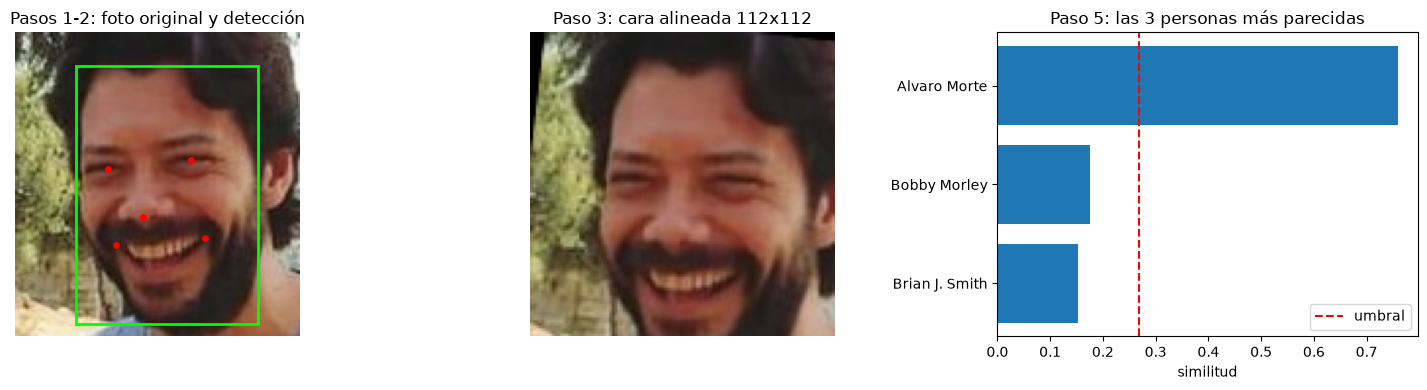

[1/5] Foto: pins_Inbar Lavi/Inbar Lavi95_1576.jpg | 255 x 270 px
[2/5] Caras detectadas: 1 | confianza: 0.864
[3/5] Cara alineada: 112 x 112 px
[4/5] Embedding de 512 valores
[5/5] Más parecida: Shakira Isabel Mebarak | similitud: 0.14 | umbral: 0.268
      Respuesta: unknown | etiqueta del dataset: Inbar Lavi


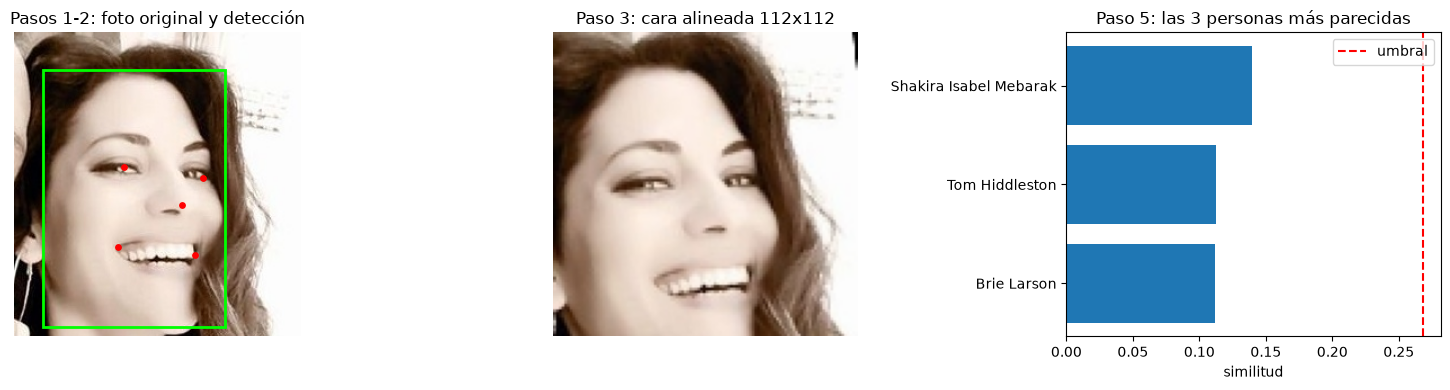

In [40]:
detector = face_pipeline.load_detector(Path("models/det_10g.onnx"))
umbral = umbral_elegido["ArcFace"]

def reconocer(c):
    # c: posición de la foto dentro de las imágenes de evaluación
    fila = filas[idx_eval[c]]

    # Paso 1: cargar la foto original
    img = cv2.imread(str(DATA_DIR / fila["ruta"]))
    print("[1/5] Foto:", fila["ruta"], "|", img.shape[1], "x", img.shape[0], "px")

    # Paso 2: detectar la cara (la de mayor confianza)
    cajas, puntos = face_pipeline.detect_with_border(detector, img)
    caja = cajas[0]
    print("[2/5] Caras detectadas:", len(cajas), "| confianza:", round(caja[4], 3))

    # Paso 3: alinear con los 5 landmarks
    cara = face_pipeline.align(img, puntos[0], 112)
    print("[3/5] Cara alineada:", cara.shape[1], "x", cara.shape[0], "px")

    # Paso 4: embedding con ArcFace
    x = face_pipeline.preprocess(cara)
    emb = face_pipeline.l2_normalize(arcface.run(None, {entrada: x})[0])
    print("[4/5] Embedding de", emb.shape[0], "valores")

    # Paso 5: similitud con cada persona registrada (la de su foto más parecida) y umbral
    sims = emb_b[galeria] @ emb
    por_persona = []
    for p in registradas:
        por_persona.append(sims[pers_eval[galeria] == p].max())
    orden = np.argsort(por_persona)[::-1]
    mejor = registradas[orden[0]]
    mejor_sim = por_persona[orden[0]]
    if mejor_sim >= umbral:
        respuesta = mejor
    else:
        respuesta = "unknown"
    print("[5/5] Más parecida:", mejor, "| similitud:", round(mejor_sim, 3), "| umbral:", round(umbral, 3))
    print("      Respuesta:", respuesta, "| etiqueta del dataset:", pers_eval[c])

    # Gráfico de los pasos
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    x1, y1, x2, y2 = caja[:4]
    axes[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", linewidth=2))
    axes[0].scatter(puntos[0][:, 0], puntos[0][:, 1], color="red", s=15)
    axes[0].set_title("Pasos 1-2: foto original y detección")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(cara, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Paso 3: cara alineada 112x112")
    axes[1].axis("off")

    nombres_top = []
    sims_top = []
    for j in orden[:3]:
        nombres_top.append(registradas[j])
        sims_top.append(por_persona[j])
    axes[2].barh(nombres_top[::-1], sims_top[::-1])
    axes[2].axvline(umbral, color="red", linestyle="--", label="umbral")
    axes[2].set_xlabel("similitud")
    axes[2].set_title("Paso 5: las 3 personas más parecidas")
    axes[2].legend()

    plt.tight_layout()
    plt.show()

# Una consulta de una persona registrada y una de una persona no registrada
reconocer(consultas[np.where(verdad != "unknown")[0][0]])
reconocer(consultas[np.where(verdad == "unknown")[0][0]])


Los dos casos salen como esperábamos:

| | Persona registrada | Persona no registrada |
|---|---|---|
| Foto original | 145×155 px | 255×270 px |
| Confianza de la detección | 0.903 | 0.864 |
| Persona más parecida en la galería | Alvaro Morte | Shakira Isabel Mebarak |
| Similitud | 0.759 | 0.14 |
| Respuesta (umbral 0.268) | **Alvaro Morte** (correcta) | **`unknown`** (correcta: Inbar Lavi no está en la galería) |

En los dos casos el detector encuentra una sola cara y ubica bien los 5 landmarks, y la alineación deja ojos y boca en la misma posición del recorte de 112×112. Para la persona registrada, la similitud con su propia galería (0.76) queda muy por encima del umbral y muy lejos de la segunda persona más parecida (0.18). Para la persona no registrada, ninguna persona de la galería pasa de 0.14, bastante por debajo del umbral, así que el sistema responde `unknown` en vez de forzar un nombre.

Es el mismo recorrido que hace la app con cada foto que recibe. Las métricas de las secciones anteriores son este mismo proceso repetido sobre todas las consultas de `test_nuevas`.

El `FutureWarning` es el mismo que aparece en la alineación: viene de InsightFace y no cambia el resultado.


## Modelo A — accuracy closed-set (test)

Hasta acá evaluamos con personas nuevas, que es lo que importa para la app. Pero la CNN también es un clasificador de las 75 personas de entrenamiento, así que medimos su accuracy sobre el split `test`. Son fotos de esas mismas 75 personas que el modelo no vio al entrenar ni se usaron para elegir la mejor época.

Es una evaluación "closed-set": cada foto pertenece seguro a una de las 75 clases, así que no hay `unknown` ni umbral. ArcFace no entra en esta comparación porque no tiene un clasificador de nuestras 75 personas.


In [41]:
idx_test = np.where(split == "test")[0]
test_loader = DataLoader(CarasDataset(idx_test, aumentar=False), batch_size=128)

modelo_a.eval()
aciertos = 0
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)
        salida = modelo_a.classifier(modelo_a(x))
        aciertos += (salida.argmax(1) == y).sum().item()

print("Fotos de test:", len(idx_test))
print("Accuracy closed-set en test:", round(aciertos / len(idx_test), 3))


Fotos de test: 1270
Accuracy closed-set en test: 0.928


El clasificador acierta el **92.8%** de las 1270 fotos de `test`, un poco menos que el 94.3% de val. Esa diferencia chica es normal: la época del modelo la elegimos mirando la loss de val, así que val queda un poco a favor. Test, en cambio, no se usó para ninguna decisión.

Es decir: **la CNN reconoce muy bien a las personas con las que se entrenó**. El problema aparece con personas nuevas, donde con un umbral seguro reconoce solo al 37% de las registradas. Esa distancia entre clasificar personas conocidas y separar personas nuevas es justamente lo que analizamos en "¿Por qué la CNN rinde menos?".


## Clustering de embeddings (test)

Para ver qué modelo agrupa mejor a cada persona, usamos los embeddings de las 15 personas de `test_nuevas`, que ningún modelo usó para entrenar ni para elegir el umbral:
- **t-SNE** de los dos modelos lado a lado, con un color por identidad.
- **K-Means con 15 clusters**, comparado con las identidades reales usando ARI y NMI (1 = los clusters coinciden con las personas).
- **Silhouette** con distancia coseno, calculada con las identidades reales: qué tan cerca está cada cara de su propia persona en comparación con la persona más cercana. Va de -1 a 1, y más alto es mejor.

CNN | ARI: 0.684 | NMI: 0.761 | Silhouette: 0.155
ArcFace | ARI: 1.0 | NMI: 1.0 | Silhouette: 0.512


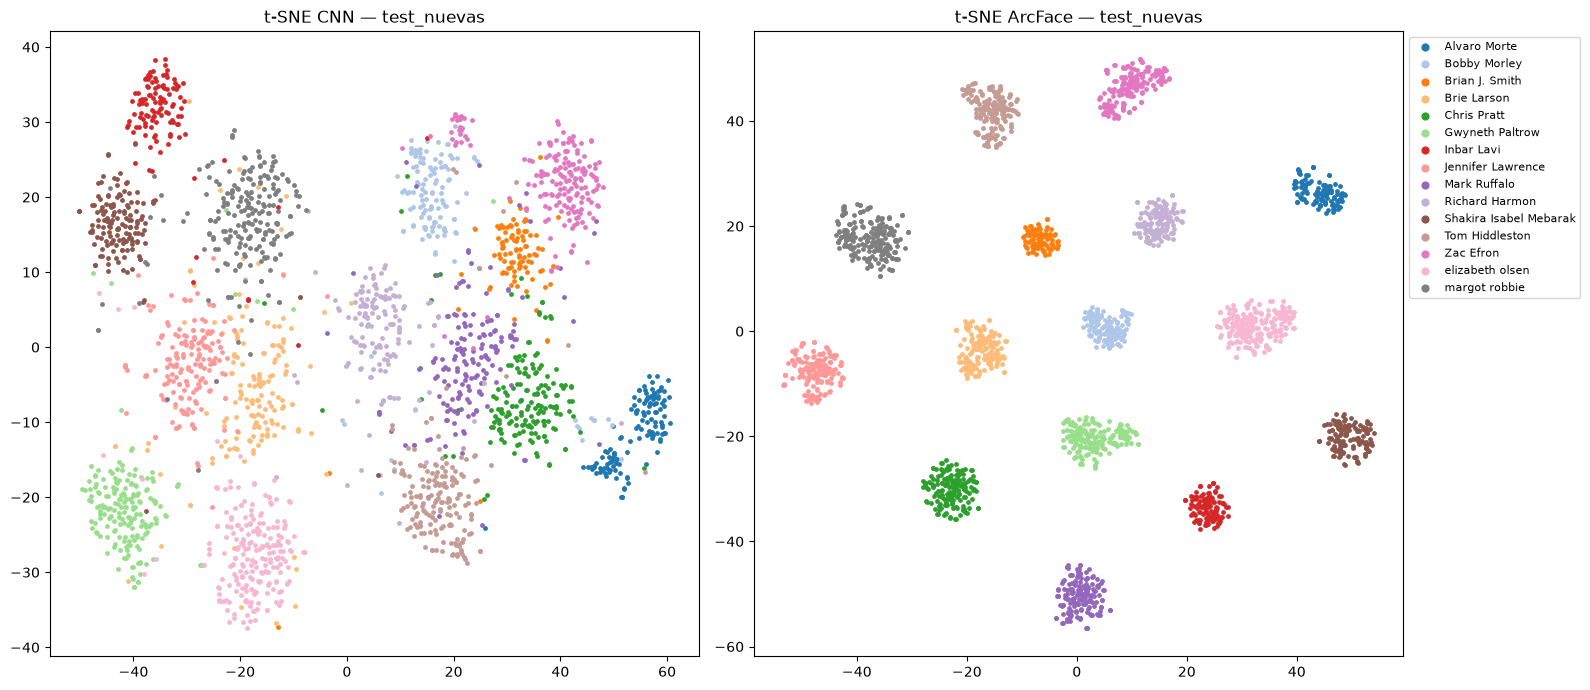

In [42]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

idx_t = np.where(split_eval == "test_nuevas")[0]
etiquetas_t = pers_eval[idx_t]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
modelos = [("CNN", emb_a), ("ArcFace", emb_b)]

for k in range(2):
    nombre, emb = modelos[k]
    e = emb[idx_t]

    kmeans = KMeans(n_clusters=15, random_state=SEED, n_init=10).fit(e)
    ari = adjusted_rand_score(etiquetas_t, kmeans.labels_)
    nmi = normalized_mutual_info_score(etiquetas_t, kmeans.labels_)
    sil = silhouette_score(e, etiquetas_t, metric="cosine")
    print(nombre, "| ARI:", round(ari, 3), "| NMI:", round(nmi, 3), "| Silhouette:", round(sil, 3))

    puntos = TSNE(n_components=2, metric="cosine", random_state=SEED).fit_transform(e)
    for j, p in enumerate(personas_test):
        m = etiquetas_t == p
        axes[k].scatter(puntos[m, 0], puntos[m, 1], s=6, color=plt.cm.tab20(j), label=p)
    axes[k].set_title("t-SNE " + nombre + " — test_nuevas")

axes[1].legend(fontsize=8, markerscale=2, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


| Métrica (test_nuevas) | CNN | ArcFace |
|---|---|---|
| ARI | 0.684 | 1.000 |
| NMI | 0.761 | 1.000 |
| Silhouette | 0.155 | 0.512 |

Con ArcFace, K-Means recupera exactamente las 15 personas (ARI y NMI = 1), y en el t-SNE se ven 15 grupos compactos y bien separados. La silhouette de 0.51 indica que cada cara está claramente más cerca de su persona que de las demás.

Con la CNN también se forman grupos por persona, así que aprendió rasgos que sirven para gente que nunca vio: K-Means acierta bastante (ARI 0.68). Pero los grupos son más dispersos, tienen puntos sueltos de otros colores y algunos se tocan, por ejemplo Jennifer Lawrence con Brie Larson. Además, Alvaro Morte aparece partido en dos grupos y Zac Efron tiene un grupito separado del principal, lo que podría deberse a condiciones de captura distintas en sus fotos. La silhouette de 0.155 es baja: en promedio, cada cara está apenas más cerca de su persona que de la persona más cercana. Eso explica por qué se superponen los histogramas de similitud.

## Análisis de errores (test)

Mostramos, para cada modelo, los peores pares de test:
- **Falsos positivos:** pares de **personas distintas** con la similitud más alta, que son los que el modelo más tiende a aceptar como la misma persona.
- **Falsos negativos:** pares de la **misma persona** con la similitud más baja, que son los que el modelo más tiende a rechazar.

Mostramos las caras alineadas, que es lo que ve el modelo. Arriba de cada foto va la etiqueta del dataset y, en la primera foto de cada par, también la similitud.

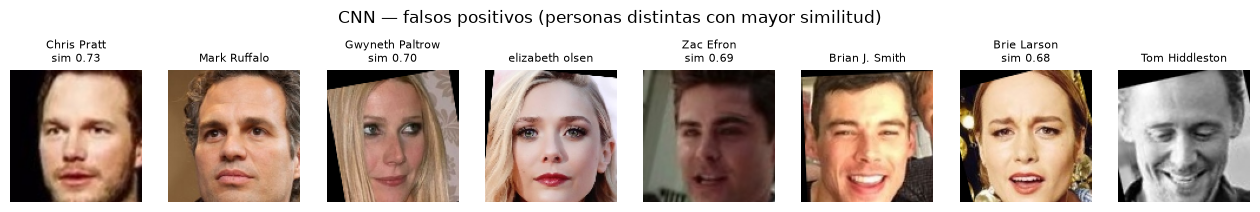

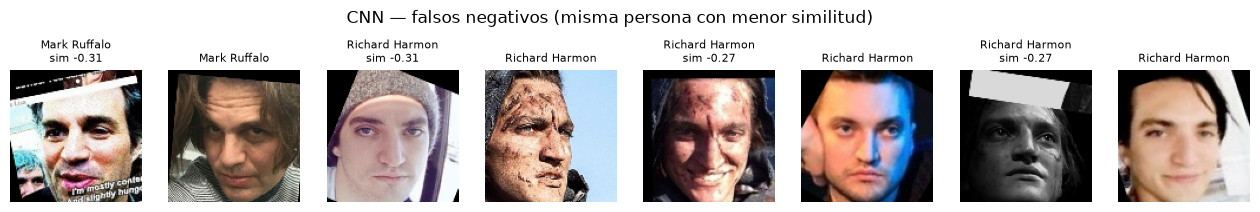

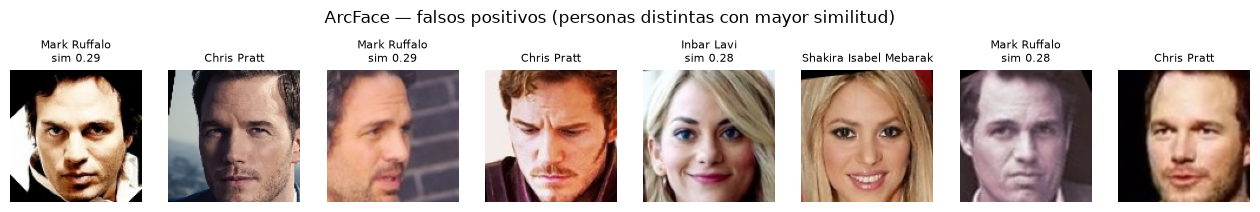

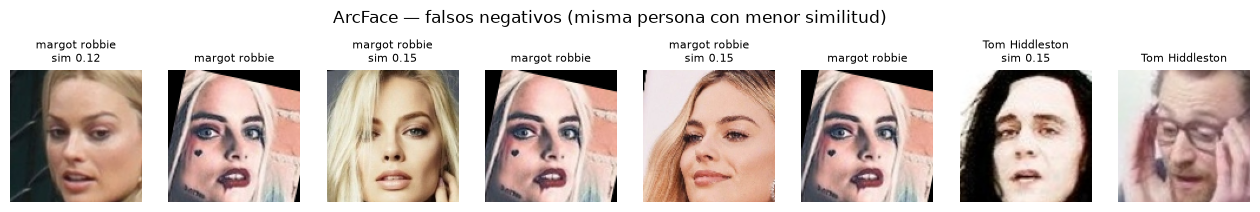

In [43]:
def mostrar_pares(lista, sim, titulo):
    fig, axes = plt.subplots(1, 2 * len(lista), figsize=(16, 2.6))
    for k in range(len(lista)):
        n = lista[k]
        i, j = pares_test[n]

        axes[2 * k].imshow(caras[idx_eval[i]])
        axes[2 * k].set_title(pers_eval[i] + f"\nsim {sim[n]:.2f}", fontsize=8)
        axes[2 * k + 1].imshow(caras[idx_eval[j]])
        axes[2 * k + 1].set_title(pers_eval[j], fontsize=8)

    for ax in axes:
        ax.axis("off")
    fig.suptitle(titulo)
    plt.show()

positivos = np.where(y_test == 1)[0]
negativos = np.where(y_test == 0)[0]

for nombre, sim in [("CNN", sim_test_a), ("ArcFace", sim_test_b)]:
    fp = negativos[np.argsort(-sim[negativos])[:4]]   # personas distintas, similitud más alta
    fn = positivos[np.argsort(sim[positivos])[:4]]    # misma persona, similitud más baja
    mostrar_pares(fp, sim, nombre + " — falsos positivos (personas distintas con mayor similitud)")
    mostrar_pares(fn, sim, nombre + " — falsos negativos (misma persona con menor similitud)")


**CNN, falsos positivos:** son pares de personas distintas con similitud muy alta, entre 0.68 y 0.73, más alta que la de muchos pares de la misma persona. En casi todos, las dos fotos son de frente, con encuadre y luz parecidos. En el par de Brie Larson con Tom Hiddleston, las caras no se parecen a simple vista y una de las dos fotos está en blanco y negro. Nuestra hipótesis es que la CNN se fija sobre todo en **pose, expresión, encuadre e iluminación**, y no tanto en los rasgos que identifican a la persona. Con solo 75 personas para entrenar, aprender eso es más fácil que aprender la identidad.

**CNN, falsos negativos:** son pares de la misma persona con similitud negativa, entre -0.31 y -0.27, como si fueran personas opuestas. En ellos aparecen las condiciones más difíciles del dataset: texto y una franja blanca encima de la cara, peinados y épocas muy distintas, un gorro, maquillaje de personaje (suciedad y heridas en la cara), luz de color muy fuerte y una foto en blanco y negro con un recorte blanco. Tres de los cuatro pares son de Richard Harmon, que es justamente una de las personas que la CNN casi no reconocía en la identificación (menos del 7%).

**ArcFace, falsos positivos:** las similitudes más altas entre personas distintas son de apenas 0.28 y 0.29, muy por debajo de las de la CNN. Quedan apenas por encima del umbral de 0.27, así que estos pares sí se aceptarían por error. Son muy pocos, y por eso la FAR en test es de solo 0.02%. Tres de los cuatro pares son entre Mark Ruffalo y Chris Pratt: hombres de pelo oscuro, con barba incipiente, en fotos de pose y luz parecidas. El otro par son dos mujeres rubias, de frente y sonriendo. Son errores de **parecido real**, que también le costarían a una persona. No podemos descartar alguna etiqueta errónea, pero no tenemos forma de comprobarlo.

**ArcFace, falsos negativos:** en tres pares, una de las fotos de Margot Robbie tiene maquillaje de personaje muy marcado (cara pintada, dibujos en la piel y pelo de colores). Es la misma foto en los tres pares, porque una misma foto puede salir sorteada en varios pares. La otra foto del par está movida y de costado, o es una foto de frente sin maquillaje. En el par de Tom Hiddleston, una foto está sobreexpuesta y con un peinado muy distinto, y en la otra hay anteojos y una mano que tapa parte de la cara (**oclusión**). Aun así, las similitudes son de 0.12 a 0.15: ArcFace las rechaza, pero no les da valores negativos como la CNN.


## Exportación del modelo A a ONNX

Exportamos la CNN a `models/custom_cnn.onnx`. Es el formato que recomienda la consigna, y la app lo carga con `onnxruntime` sin necesitar el código de la clase. Solo se exporta la parte que genera el embedding: el clasificador de 75 personas no se usa en la app.

- `opset_version=17`: una versión de ONNX que también puede leer el `onnxruntime` más viejo del `requirements.txt` de la app (1.24.4).
- `dynamo=False`: usa el exportador clásico, que no necesita instalar `onnxscript`.
- El tamaño del batch queda libre (`dynamic_axes`), así la app puede pasar una o varias caras.

Después controlamos que el `.onnx` dé el mismo embedding que el modelo de PyTorch.

El archivo no se sube al repo (está en el `.gitignore`). Lo compartimos en un link público de solo lectura, que va en el README y en el PR.


In [44]:
import copy

ARCHIVO_ONNX_A = "models/custom_cnn.onnx"
modelo_cpu = copy.deepcopy(modelo_a).cpu().eval()   # copia en CPU, el original queda en la GPU

torch.onnx.export(
    modelo_cpu,
    torch.zeros(1, 3, 112, 112),
    ARCHIVO_ONNX_A,
    input_names=["input"],
    output_names=["embedding"],
    dynamic_axes={"input": {0: "batch"}, "embedding": {0: "batch"}},
    opset_version=17,
    dynamo=False,
)

# Control: el .onnx tiene que dar el mismo embedding que PyTorch
sesion_a = onnxruntime.InferenceSession(ARCHIVO_ONNX_A)
cara_bgr = cv2.cvtColor(caras[idx_eval[0]], cv2.COLOR_RGB2BGR)
x = face_pipeline.preprocess(cara_bgr)
e = face_pipeline.l2_normalize(sesion_a.run(None, {"input": x})[0])
print("Diferencia máxima con PyTorch:", np.abs(e - emb_a[0]).max())


C:\Users\maximiliano.chiappe\AppData\Local\Temp\ipykernel_28292\1049741926.py:6: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Diferencia máxima con PyTorch: 8.568168e-08


El `.onnx` da el mismo embedding que el modelo de PyTorch: la diferencia máxima es de 0.00000009, que es error de redondeo. El `DeprecationWarning` solo avisa que existe un exportador más nuevo y no cambia el archivo.


## Costo computacional

Comparamos los dos modelos tal como los usaría la app: los dos en ONNX, corriendo con `onnxruntime` en **CPU**.
- **Tamaño** del archivo en MB y **cantidad de parámetros**, contados desde el `.onnx`.
- **Tiempo de inferencia por rostro:** el promedio de 200 caras procesadas de a una, después de una primera corrida de calentamiento. No incluye la detección, que es la misma para los dos modelos.
- **Dimensión del embedding.**


In [45]:
import os
import time
import onnx

def parametros_onnx(ruta):
    modelo = onnx.load(ruta)
    total = 0
    for t in modelo.graph.initializer:
        total += int(np.prod(t.dims))
    return total

def ms_por_cara(sesion, n=200):
    nombre_entrada = sesion.get_inputs()[0].name
    xs = []
    for i in idx_eval[:n]:
        cara_bgr = cv2.cvtColor(caras[i], cv2.COLOR_RGB2BGR)
        xs.append(face_pipeline.preprocess(cara_bgr))

    sesion.run(None, {nombre_entrada: xs[0]})   # calentamiento
    inicio = time.time()
    for x in xs:
        sesion.run(None, {nombre_entrada: x})
    return (time.time() - inicio) / n * 1000

modelos = [("CNN", ARCHIVO_ONNX_A, sesion_a), ("ArcFace", "models/w600k_r50.onnx", arcface)]
for nombre, ruta, sesion in modelos:
    tamano = os.path.getsize(ruta) / 1e6
    print(nombre,
          "| tamaño:", round(tamano, 1), "MB",
          "| parámetros:", parametros_onnx(ruta),
          "| ms por cara (CPU):", round(ms_por_cara(sesion), 1),
          "| embedding:", sesion.get_outputs()[0].shape[1])

CNN | tamaño: 7.3 MB | parámetros: 1833280 | ms por cara (CPU): 1.9 | embedding: 512
ArcFace | tamaño: 174.4 MB | parámetros: 43590976 | ms por cara (CPU): 82.1 | embedding: 512


| | CNN | ArcFace |
|---|---|---|
| Tamaño | 7.3 MB | 174.4 MB |
| Parámetros | 1.8 millones | 43.6 millones |
| Tiempo por cara (CPU) | 1.9 ms | 82.1 ms |
| Embedding | 512 | 512 |

La CNN es **24 veces más chica y unas 40 veces más rápida** que ArcFace. Los tiempos cambian un poco entre corridas según la carga de la PC, pero la diferencia entre los dos modelos se mantiene. Igual, los ~80 ms de ArcFace no son un problema para la app: una foto con un par de caras se procesa en bastante menos de un segundo, sumando la detección. Los dos generan embeddings de 512, así que cualquiera de los dos funciona con `EMBEDDING_DIM=512` sin tocar la base de datos.

La CNN tiene 32 parámetros más en el `.onnx` que en PyTorch (1833280 contra 1833248), por cómo el exportador guarda las capas de BatchNorm. Es una diferencia despreciable.

## Comparación final y elección

Salvo el accuracy closed-set, todas las métricas son sobre las 15 personas de `test_nuevas`, que ningún modelo usó para entrenar ni para elegir el umbral. Los umbrales se calibraron en `val_nuevas` para FAR = 1e-3.

| Métrica | CNN propia (A) | ArcFace (B) |
|---|---|---|
| **Clasificación** (75 personas conocidas) | | |
| Accuracy closed-set en `test` | 92.8% | — (no tiene clasificador de nuestras personas) |
| **Verificación** | | |
| AUC | 0.901 | 1.000 |
| EER | 18.5% | 0.17% |
| TAR@FAR=1e-2 | 31.0% | 99.9% |
| TAR@FAR=1e-3 | 13.4% | 99.8% |
| **Umbral** | | |
| Umbral calibrado (val, FAR=1e-3) | 0.618 | 0.268 |
| FAR / FRR en test con ese umbral | 0.08% / 88.9% | 0.02% / 0.34% |
| **Identificación** (10 registradas, 5 desconocidas) | | |
| Top-1 / Top-5 | 77.2% / 98.6% | 100% / 100% |
| Precision / Recall / F1 (macro) | 0.843 / 0.423 / 0.486 | 1.000 / 1.000 / 1.000 |
| Desconocidos rechazados | 95.4% | 100% |
| Registrados reconocidos | 37.4% | 100% |
| Consultas mal identificadas | 968 de 2372 | 0 de 2372 |
| **Clustering** | | |
| ARI / NMI | 0.684 / 0.761 | 1.000 / 1.000 |
| Silhouette | 0.155 | 0.512 |
| **Costo** | | |
| Tamaño / parámetros | 7.3 MB / 1.8 M | 174.4 MB / 43.6 M |
| Tiempo por cara (CPU) | 1.9 ms | 82.1 ms |
| Embedding | 512 | 512 |
| **Otros** | | |
| Licencia | Propia | Solo investigación no comercial (según el README de InsightFace) |
| Integración en la app | `.onnx` propio | `.onnx` de `buffalo_l`, ya integrado |

### Elegimos ArcFace (`w600k_r50.onnx`) para la app

- **Desempeño:** es muy superior en todas las métricas sobre personas nuevas. Con un umbral seguro reconoce al 100% de las personas registradas y rechaza a todos los desconocidos. La CNN, con ese mismo nivel de seguridad, solo reconoce al 37%, y en la práctica la app casi siempre respondería `unknown`.
- **Costo:** es unas 40 veces más lento que la CNN, pero ~80 ms por cara en CPU es aceptable para una app que procesa fotos de a una.
- **Licencia:** sus pesos son solo para investigación no comercial. Para este TP está bien. En un producto comercial habría que licenciarlo o reemplazarlo por un modelo propio.
- **Integración:** ya es el modelo que configuramos en la app (`MODEL_NAME=w600k_r50.onnx`). Usa la misma alineación de 112×112 y el mismo preprocesamiento de `face_pipeline`, y genera embeddings de 512.

En `.env.docker.example` y `.env.local.example` dejamos **`SIMILARITY_THRESHOLD=0.27`**, el umbral calibrado en val. El valor que traía la app (0.55) rechazaría a más de un tercio de las personas registradas.

### ¿Por qué la CNN rinde menos?

- **Datos:** la entrenamos con 75 personas y unas 9600 fotos. ArcFace se entrenó con unas 600 mil personas. Para aprender qué hace distinta a una cara de otra hacen falta muchísimas identidades, no solo muchas fotos de pocas personas. Se ve en los números: con las 75 personas de entrenamiento acierta el 92.8%, pero con personas nuevas el rendimiento cae mucho.
- **Loss:** con softmax, la red aprende a separar a las 75 personas de train, pero nada la obliga a dejar márgenes grandes entre personas. La loss de ArcFace sí agrega un margen angular, y por eso sus embeddings separan mucho mejor a personas que nunca vio.
- **Lo que aprendió:** en el análisis de errores vimos que la CNN se guía mucho por pose, luz y encuadre. Con pocas personas, esas condiciones alcanzan para clasificar train, pero no generalizan.
- **Tamaño:** tiene 1.8 millones de parámetros, contra 43.6 millones de ArcFace.

Aun así, la CNN aprendió algo útil: un AUC de 0.90 y un Top-1 de 77% con personas que nunca vio están muy por encima del azar (10% de Top-1 con 10 personas). Para mejorarla probaríamos, en este orden: la loss ArcFace en lugar de softmax, más identidades para entrenar (por ejemplo, las 105 de Pins o un dataset más grande) y un fine-tuning de un backbone preentrenado como ResNet-18.

### Modelos exportados

- CNN propia: `models/custom_cnn.onnx` → link de descarga: https://drive.google.com/file/d/195_t7-_7z0snfGOiDSyX7PpTPVIg8ZXB/view?usp=sharing
- ArcFace: `w600k_r50.onnx` del paquete `buffalo_l` de InsightFace → link de descarga: https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip

Los pesos no se suben al repo (están en el `.gitignore`).
